### Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from tensorflow.keras.models import load_model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


### Loading the trained model and test data

In [2]:
model = load_model("../models/disease_ann_model.keras")

X_test = np.load("../data/processed/X_test.npy")
y_test = np.load("../data/processed/y_test.npy")

label_encoder = joblib.load("../models/label_encoder.pkl")

print("Model loaded successfully!")
print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)
print("Disease classes:", len(label_encoder.classes_))

Model loaded successfully!
Test features shape: (61, 131)
Test target shape: (61,)
Disease classes: 41


### Evaluating the ANN model

In [3]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nANN MODEL PERFORMANCE")
print("-" * 40)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step - accuracy: 0.9836 - loss: 0.0191

ANN MODEL PERFORMANCE
----------------------------------------
Test Loss: 0.0191
Test Accuracy: 98.36 %


### Generating predictions

In [4]:
y_probabilities = model.predict(X_test)

y_pred = np.argmax(y_probabilities, axis=1)

print("Predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 209ms/step
Predictions generated successfully!
Actual labels: [19 10  4 26 15 13 20 10 30 30]
Predicted labels: [19 10  4 26 15 13 20 10 30 30]


### Converting numerical labels back into disease names

In [5]:
actual_diseases = label_encoder.inverse_transform(y_test)

predicted_diseases = label_encoder.inverse_transform(y_pred)

results_df = pd.DataFrame({
    "Actual Disease": actual_diseases,
    "Predicted Disease": predicted_diseases,
    "Correct Prediction": actual_diseases == predicted_diseases
})

results_df.head(15)

,Actual Disease,Predicted Disease,Correct Prediction
0,hepatitis a,hepatitis a,True
1,common cold,common cold,True
2,allergy,allergy,True
3,hypoglycemia,hypoglycemia,True
4,fungal infection,fungal infection,True
5,dimorphic hemmorhoids(piles),dimorphic hemmorhoids(piles),True
6,hepatitis b,hepatitis b,True
7,common cold,common cold,True
8,malaria,malaria,True
9,malaria,malaria,True


### Calculating evaluation metrics

In [6]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("MODEL EVALUATION METRICS")
print("-" * 40)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

MODEL EVALUATION METRICS
----------------------------------------
Accuracy : 0.9836
Precision: 0.9727
Recall   : 0.9836
F1 Score : 0.977


### Generating classification report

In [7]:
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print("=" * 60)

print(report)

CLASSIFICATION REPORT
                                         precision    recall  f1-score   support

(vertigo) paroymsal  positional vertigo       1.00      1.00      1.00         1
                                   acne       1.00      1.00      1.00         1
                                   aids       1.00      1.00      1.00         1
                    alcoholic hepatitis       1.00      1.00      1.00         2
                                allergy       1.00      1.00      1.00         1
                              arthritis       1.00      1.00      1.00         1
                       bronchial asthma       1.00      1.00      1.00         1
                   cervical spondylosis       1.00      1.00      1.00         1
                            chicken pox       1.00      1.00      1.00         2
                    chronic cholestasis       1.00      1.00      1.00         2
                            common cold       1.00      1.00      1.00         2
     

### Generating confusion matrix

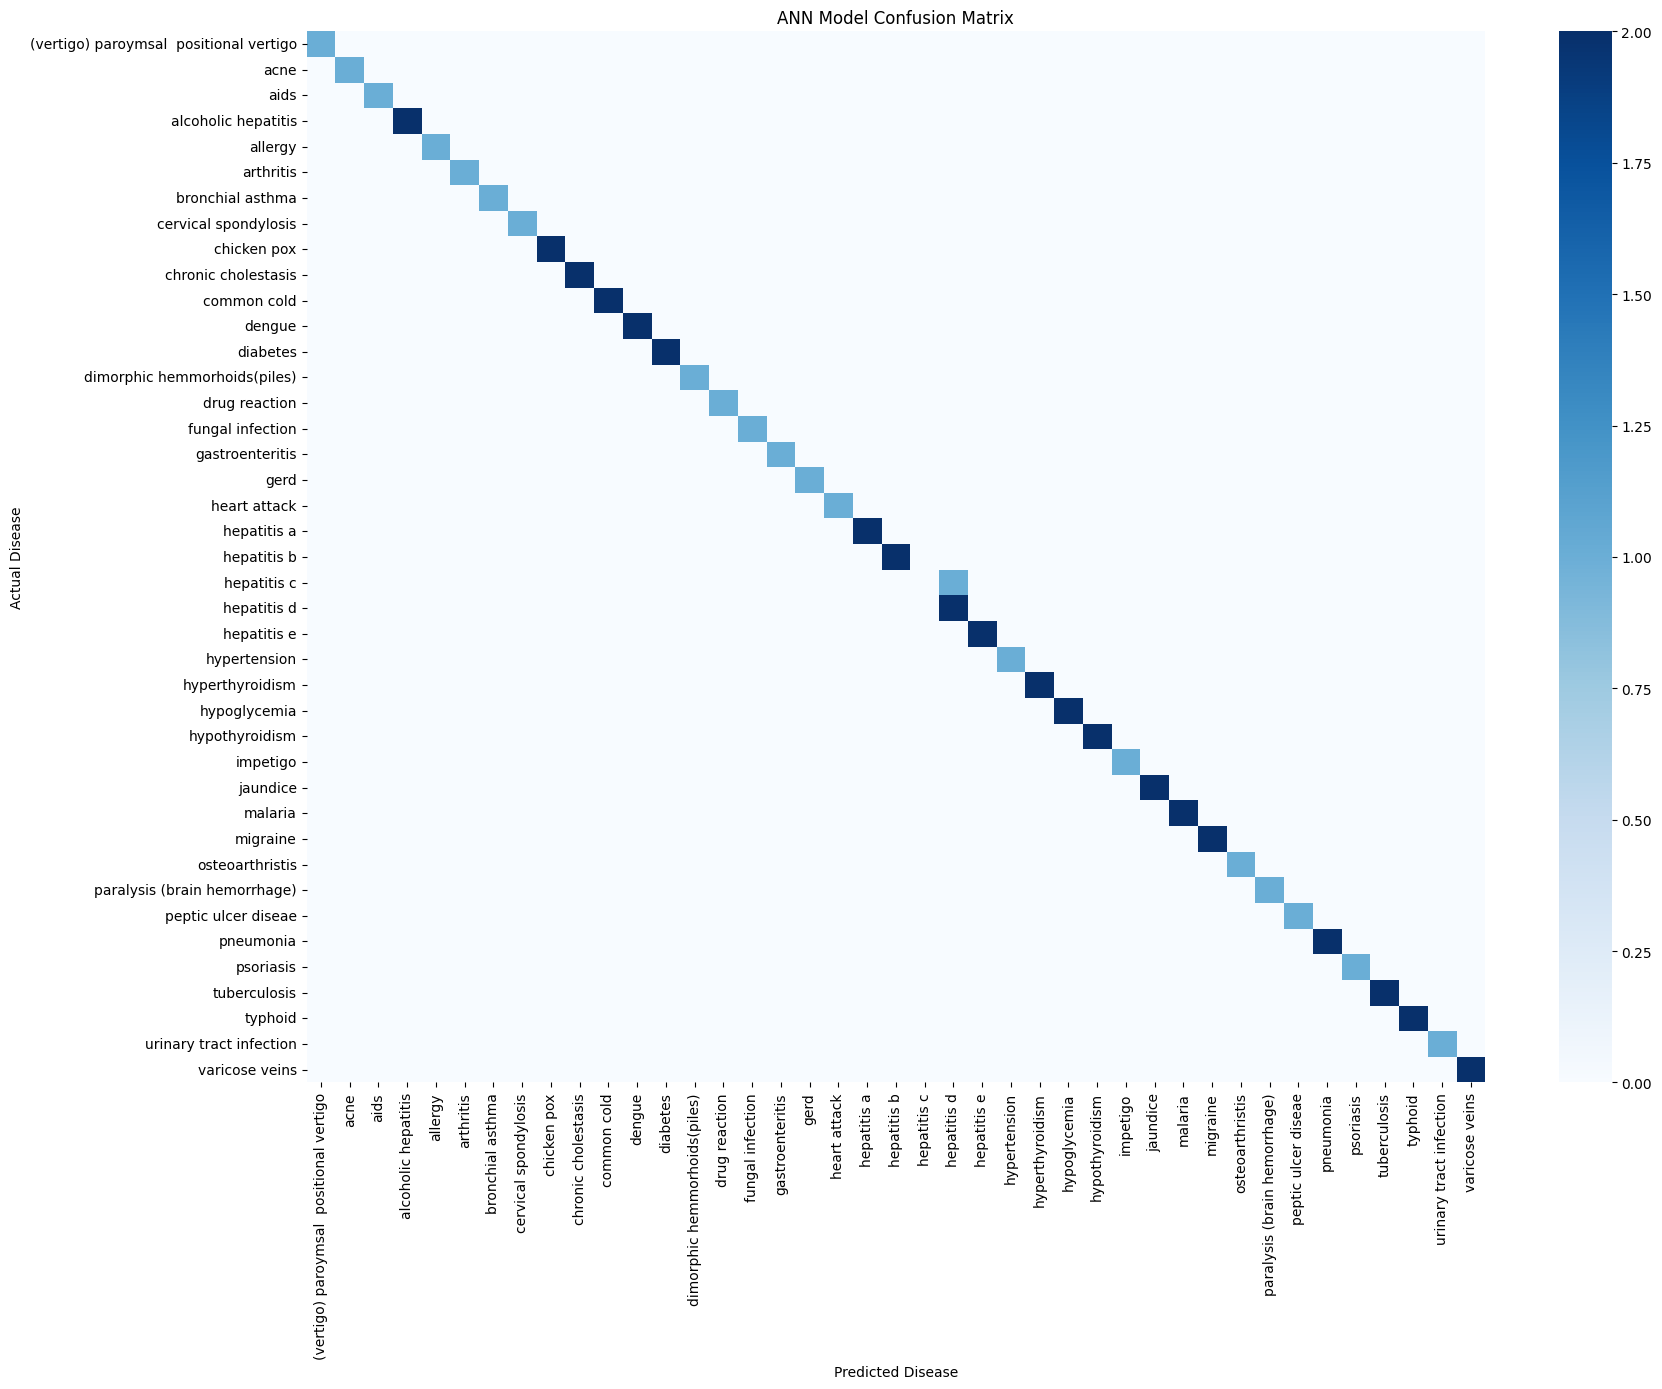

In [8]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("ANN Model Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Checking incorrect predictions

In [9]:
incorrect_predictions = results_df[
    results_df["Correct Prediction"] == False
]

print("Total test records:", len(results_df))

print("Correct predictions:",
      results_df["Correct Prediction"].sum())

print("Incorrect predictions:",
      len(incorrect_predictions))

print("\nIncorrect prediction examples:")

incorrect_predictions.head(20)

Total test records: 61
Correct predictions: 60
Incorrect predictions: 1

Incorrect prediction examples:


,Actual Disease,Predicted Disease,Correct Prediction
23,hepatitis c,hepatitis d,False


### Saving evaluation results

In [10]:
os.makedirs("../reports", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

results_df.to_csv(
    "../data/processed/prediction_results.csv",
    index=False
)

with open("../reports/ann_evaluation_report.txt", "w") as file:

    file.write("ANN MODEL EVALUATION REPORT\n")
    file.write("=" * 45 + "\n\n")

    file.write(f"Accuracy: {accuracy:.4f}\n")
    file.write(f"Precision: {precision:.4f}\n")
    file.write(f"Recall: {recall:.4f}\n")
    file.write(f"F1 Score: {f1:.4f}\n\n")

    file.write("CLASSIFICATION REPORT\n")
    file.write(report)

print("Evaluation reports saved successfully!")

Evaluation reports saved successfully!
